In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

In [52]:
def plot_variation_convergence(percentiles, param_name, rsd_suff):
    """
    Plots VVF percentile derivatives for 2.5% and 5% variations alongside their fractional difference.
    """
    deriv_2_5 = Table.read(f'derivatives/2_5/dVVF_d{param_name}_{rsd_suff}.fits').as_array()
    deriv_5 = Table.read(f'derivatives/5/dVVF_d{param_name}_{rsd_suff}.fits').as_array()
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
    
    # Top Panel: Absolute Derivative Values
    ax1.plot(percentiles, deriv_2_5, marker='o', linestyle='-', color='royalblue', label='2.5% Variation')
    ax1.plot(percentiles, deriv_5, marker='x', linestyle='--', color='darkorange', label='5.0% Variation')
    
    ax1.set_ylabel(fr'$\partial(\mathrm{{VVF}}) / \partial {param_name}$')
    ax1.set_title('Convergence of VVF Derivatives (2.5% vs 5.0% Variation)')
    ax1.grid(True, linestyle=':', alpha=0.7)
    ax1.legend()
    
    # Bottom Panel: Fractional Difference (Residuals)
    # Adding a small epsilon to avoid division by zero in zero-crossing regions
    val_2_5 = deriv_2_5[deriv_2_5.dtype.names[0]]
    val_5 = deriv_5[deriv_5.dtype.names[0]]
    fractional_diff = np.abs((val_5 - val_2_5) / (val_2_5)) * 100
    
    ax2.plot(percentiles, fractional_diff, marker='s', color='gray', markersize=4, linestyle='-')
    ax2.axhline(0, color='black', linewidth=1)
    
    ax2.set_xlabel('VVF Percentile')
    ax2.set_ylabel('% Difference')
    ax2.grid(True, linestyle=':', alpha=0.7)
    
    plt.tight_layout()
    plt.savefig(f'derivatives/plots/dVVF_d{param_name}_{rsd_suff}.pdf')
    plt.show()
  


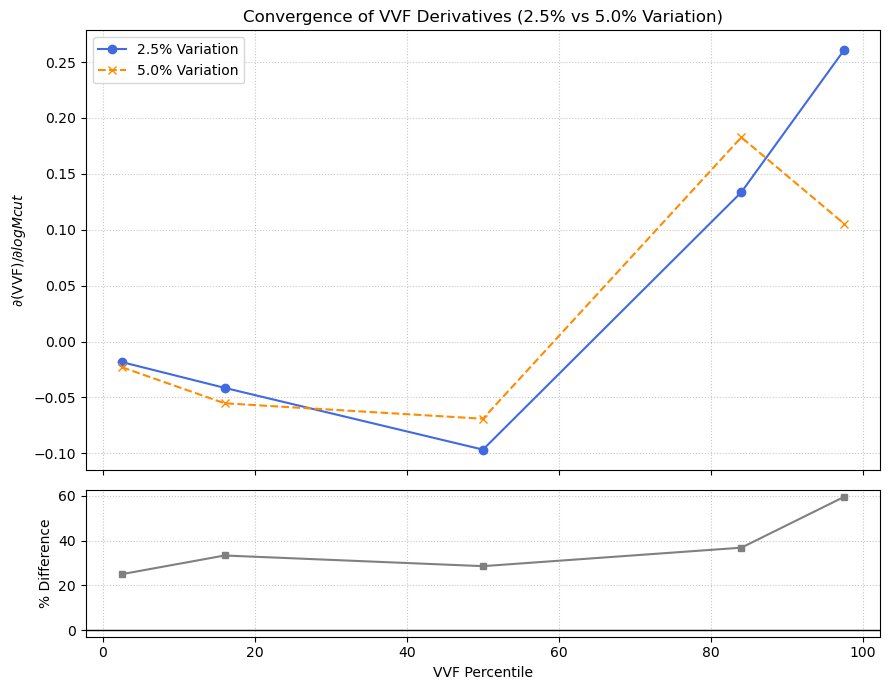

In [57]:
param = 'logMcut'
percentiles = [2.5, 16.0, 50.0, 84.0, 97.5]
suff = 'rsd'
plot_variation_convergence(percentiles=percentiles, param_name=param, rsd_suff=suff)

In [31]:
deriv_2_5 = Table.read(f'derivatives/2_5/dVVF_dalpha_rsd.fits').as_array()
deriv_5 = Table.read(f'derivatives/5/dVVF_dalpha_rsd.fits').as_array()
val_2_5 = deriv_2_5[deriv_2_5.dtype.names[0]]
val_5 = deriv_5[deriv_5.dtype.names[0]]

In [32]:
val_5

array([-0.07554364, -0.16997318, -0.18526178,  0.03057719,  1.42404252])

In [33]:
val_2_5

array([-0.06475169, -0.16367788, -0.19245641,  0.06655035,  0.9299062 ])